# Kernels and feature maps on a real photo

Booster LEAP, Computer Vision, topic 2. What does a convolution kernel see in a photograph, what do ReLU and pooling keep, and how far does one pixel reach?

<h1 style="color:#b45309">&#9888; First: File &rarr; Save a copy in Drive</h1>

<span style="font-size:20px">This notebook is read-only. Make your own copy now, then work in the copy (no GitHub login needed).</span>

**How to use this notebook:** run the cells from top to bottom (Runtime, Run all, or Shift+Enter on each cell). It needs no GPU. It loads three real photographs from our public GitHub repository (an internet connection is needed, Colab has one). Photos: china.jpg and flower.jpg are scikit-learn sample images (Flickr users danielbuechele and vultilion, CC BY 2.0); grace_hopper.jpg is a U.S. Navy photograph, public domain. Change one thing at a time and run again; the last cell tells you what to try, including your own photo.

## 1. Load a photo as a grey picture

A convolution works on one channel at a time. We use the grey version of the photo (float numbers) so that we can watch one feature map.

china shape (height, width, channels): (427, 640, 3)  dtype: uint8  values 0 to 255


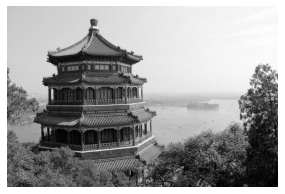

In [ ]:
import io, urllib.request
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/boosterleap/booster-leap-notebooks/main/computer-vision/images/"
FILES = {"china": "china.jpg", "flower": "flower.jpg", "hopper": "grace_hopper.jpg"}

def load_photo(name):
    """one of the three photos of the course, as a PIL image"""
    data = urllib.request.urlopen(BASE + FILES[name]).read()
    return Image.open(io.BytesIO(data)).convert("RGB")

# Your own photo (optional): remove the # signs, run the cell, choose a file.
# from google.colab import files
# photo = Image.open(next(iter(files.upload()))).convert("RGB")

NAME = "china"          # change to "flower" or "hopper"
photo = load_photo(NAME)
img = np.asarray(photo)
print(NAME, "shape (height, width, channels):", img.shape, " dtype:", img.dtype, " values", img.min(), "to", img.max())

g = img @ np.array([0.299, 0.587, 0.114])
plt.figure(figsize=(5, 3.4)); plt.imshow(g, cmap="gray"); plt.axis("off"); plt.show()

## 2. Five kernels

`conv(g, k)` slides the kernel over the picture without padding and without flipping it (this is what deep-learning libraries call convolution): every output value is the sum of kernel times the 3 x 3 neighbourhood. The output is 2 pixels smaller in each direction.

box blur                     output (425, 638)  min      0.5  max    254.0  mean absolute  144.76
sharpen                      output (425, 638)  min   -510.9  max    971.7  mean absolute  164.84
vertical edges (Sobel x)     output (425, 638)  min   -921.7  max    867.2  mean absolute   55.78
horizontal edges (Sobel y)   output (425, 638)  min   -806.4  max    891.0  mean absolute   55.57
outline (Laplacian)          output (425, 638)  min  -1114.9  max   1533.8  mean absolute   90.33


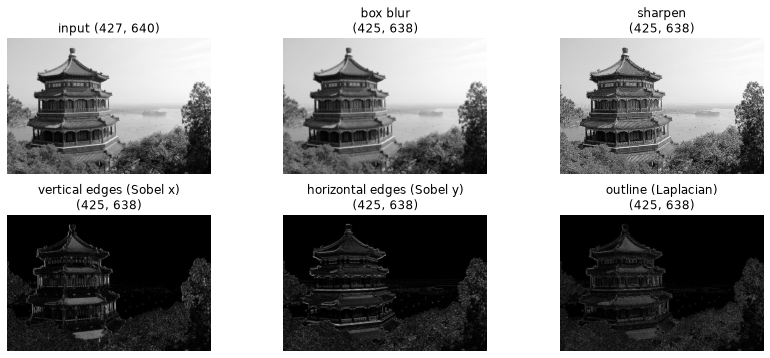

In [ ]:
def conv(x, k):
    h, w = k.shape
    out = np.zeros((x.shape[0] - h + 1, x.shape[1] - w + 1))
    for j in range(h):
        for i in range(w):
            out += k[j, i] * x[j:j + out.shape[0], i:i + out.shape[1]]
    return out

KERNELS = {
    "box blur": np.ones((3, 3)) / 9,
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "vertical edges (Sobel x)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "horizontal edges (Sobel y)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "outline (Laplacian)": np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]]),
}
maps = {name: conv(g, k) for name, k in KERNELS.items()}
fig, ax = plt.subplots(2, 3, figsize=(12, 5.2))
ax = ax.ravel(); ax[0].imshow(g, cmap="gray"); ax[0].set_title(f"input {g.shape}")
for a, (name, m) in zip(ax[1:], maps.items()):
    a.imshow(np.abs(m) if "edges" in name or "outline" in name else np.clip(m, 0, 255), cmap="gray"); a.set_title(f"{name}\n{m.shape}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
for name, m in maps.items():
    print(f"{name:28s} output {m.shape}  min {m.min():8.1f}  max {m.max():8.1f}  mean absolute {np.abs(m).mean():7.2f}")

## 3. ReLU and max pooling

ReLU keeps only the positive responses. Max pooling with a 2 x 2 window and stride 2 keeps the largest value of each block, so the map becomes half as wide and high. We count how much of the strong response survives.

feature map (425, 638) -> after ReLU the share of positive values is 0.495
after 2 x 2 max pooling the map is (212, 319)
values above half of the maximum: 1736 before pooling, 1154 after pooling


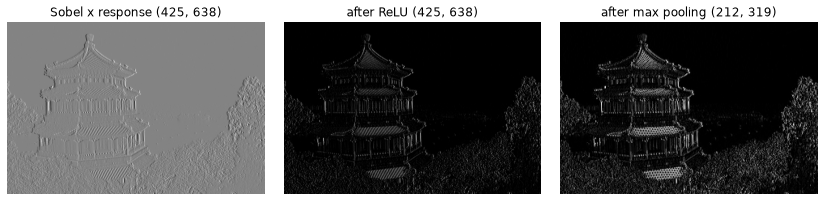

In [ ]:
def relu(m):
    return np.maximum(m, 0)

def maxpool2(m):
    h, w = (m.shape[0] // 2) * 2, (m.shape[1] // 2) * 2
    return m[:h, :w].reshape(h // 2, 2, w // 2, 2).max(axis=(1, 3))

m = maps["vertical edges (Sobel x)"]
r = relu(m); p = maxpool2(r)
limit = 0.5 * r.max()
print(f"feature map {m.shape} -> after ReLU the share of positive values is {(m > 0).mean():.3f}")
print(f"after 2 x 2 max pooling the map is {p.shape}")
print(f"values above half of the maximum: {(r > limit).sum()} before pooling, {(p > limit).sum()} after pooling")
fig, ax = plt.subplots(1, 3, figsize=(12, 2.8))
for a, im, t in zip(ax, [m, r, p], ["Sobel x response", "after ReLU", "after max pooling"]):
    a.imshow(im, cmap="gray"); a.axis("off"); a.set_title(f"{t} {im.shape}")
plt.tight_layout(); plt.show()

## 4. Does pooling forgive a one-pixel shift?

We compute the ReLU map for the photo and for the same photo shifted by one pixel, and measure how different the two maps are (mean absolute difference divided by the mean of the first map). Then the same after max pooling.

In [ ]:
a = relu(conv(g[:, :-1], KERNELS["vertical edges (Sobel x)"]))
b = relu(conv(g[:, 1:], KERNELS["vertical edges (Sobel x)"]))
def change(u, v):
    return np.abs(u - v).mean() / u.mean()
print(f"one-pixel shift: change of the ReLU map {change(a, b):.3f}, change after 2 x 2 max pooling {change(maxpool2(a), maxpool2(b)):.3f}")
a2, b2 = a[:, :-1], b[:, 1:]    # a shift of two pixels in total
print(f"two columns apart:   ReLU map {change(a2, b2[:, :]):.3f}, pooled {change(maxpool2(a2), maxpool2(b2)):.3f}")

one-pixel shift: change of the ReLU map 1.253, change after 2 x 2 max pooling 0.601
two columns apart:   ReLU map 1.698, pooled 1.014


## 5. The receptive field, measured

We stack two 3 x 3 layers (the outline kernel and ReLU, then a 3 x 3 box sum). In theory one input pixel reaches a 5 x 5 block of outputs. We change one pixel and count the outputs that really change. With three layers the block grows to 7 x 7.

In [ ]:
LAP = KERNELS["outline (Laplacian)"]; BOX = np.ones((3, 3))
def stack(x, layers):
    y = x
    for _ in range(layers):
        y = relu(conv(y, LAP)) if _ == 0 else conv(y, BOX)
    return y

y0, x0 = g.shape[0] // 2, g.shape[1] // 2          # a pixel in the middle of the photo
for layers in (2, 3):
    before = stack(g, layers)
    g2 = g.copy(); g2[y0, x0] += 60
    changed = (stack(g2, layers) != before).sum()
    side = 2 * layers + 1
    print(f"{layers} layers: at most {side * side} outputs can change ({side} x {side}), {changed} really changed")

2 layers: at most 25 outputs can change (5 x 5), 20 really changed
3 layers: at most 49 outputs can change (7 x 7), 42 really changed


## Try it yourself

1. Write your own 3 x 3 kernel in `KERNELS` (for example an emboss `[[-2, -1, 0], [-1, 1, 1], [0, 1, 2]]`) and look at its map.
2. Change `NAME` to `"hopper"`. Which kernel shows the most structure in a portrait? Which in the pagoda?
3. In section 3 change the limit from half of the maximum to a quarter. Do more strong responses survive pooling?
4. In section 5 add `delta = -255` instead of `+60`. Why can the number of changed outputs be smaller than the theoretical block?
5. Try your own photo (see the first notebook cell) and compare the share of positive values after ReLU for a smooth photo and a busy one.